In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os



# Remove catchments below a certain area threshold

To limit the number of basins, we have two options:

1. Drop anything below a user-supplied threshold. Con: end result doesn't include the full land area.
2. To still include the full land area: remove small basins (less than a user-supplied threshold, e.g. 10 km2) and set their corresponding pixels to NoData. Then, allocate these pixels to their nearest valid basin using the wbt.euclidean_allocation tool. This may also assign oceanic pixels, so introduce an additional step to mask out the ocean (e.g. workflow followed by Igneczi & Bamber (2025)).


To avoid rasters:

* Find nearest large-basin polygon for each small-basin polygon
* Dissolve small polygon into nearest one

This uses basin centroids, not pixel distance. It’s simpler but less hydrologically correct.

# TO DO:
- Non-Norwegian rivers? Lots of rivers seem to go over the border to Sweden (in particular). Catchments totally wrong? What to do about cross-border catchments for NorSink?
- Need to allocate land that wasn't part of a hovedelv catchment to a hovedelv catchment too.
- Method for merging small catchments into bigger nearby ones might not be good. Centroid based. Could get merging across fjords and other oddities. Maybe that's ok, but explore e.g. in QGIS.
- ...

In [2]:
# User input

# Directory to read raw shapefile from and to write processed shp to
cur_dir = r"/home/jovyan/shared/common/norsink/spatial/coastal_drainage_basins"

min_cat_size = 10  # km2
small_cat_method = "merge"  # "drop" or "merge"

In [3]:
# Read input
sea_gdf = gpd.read_file(os.path.join(cur_dir, "shp", "sea.shp"))
riv_gdf = gpd.read_file(os.path.join(cur_dir, "shp", "rivers.shp"))
outlet_gdf = gpd.read_file(os.path.join(cur_dir, "shp", "outlets_all.shp"))

In [4]:
cat_gdf = gpd.read_file(os.path.join(cur_dir, "shp", "catchments_all.shp"))

cat_gdf.head()

,elvid,nbfVassNr,easting,northing,latitude,longitude,area_km2,geometry
0,0,022.32Z,57644.761863,6.455798e+06,58.022290,7.502217,1.231893,"POLYGON ((58200 6456760, 58320 6456760, 58320 ..."
1,1,022.43Z,51780.981208,6.457149e+06,58.028450,7.401257,10.104939,"MULTIPOLYGON (((52000 6457680, 52000 6457640, ..."
2,2,022.3Z,64044.032832,6.457637e+06,58.044984,7.606244,39.289173,"MULTIPOLYGON (((66200 6458160, 66200 6458120, ..."
3,6,022.4Z,52223.007045,6.459131e+06,58.046539,7.404913,22.756594,"POLYGON ((54960 6466240, 55000 6466240, 55000 ..."
4,10,023.22Z,34091.759523,6.456831e+06,58.007450,7.105193,5.794413,"POLYGON ((32400 6460240, 32560 6460240, 32560 ..."


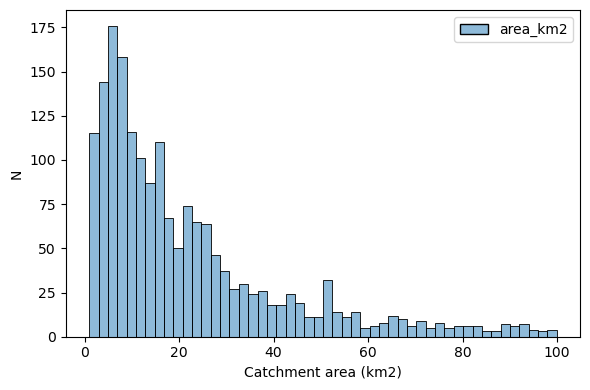

In [5]:
# Quick look at histogram of catchment areas
max_area_plot = 100
plt.figure(figsize=(6,4))
sns.histplot(cat_gdf.loc[cat_gdf["area_km2"] < max_area_plot, ["area_km2"]], bins=50, kde=False, color="steelblue")
plt.xlabel("Catchment area (km2)")
plt.ylabel("N")
# plt.xscale('log')
# plt.yscale('log')
plt.tight_layout()
plt.show()

In [6]:
if small_cat_method == 'drop':
    select_cats_gdf = cat_gdf.loc[cat_gdf['area_km2'] >= min_cat_size, :].copy()

if small_cat_method == 'merge':

    select_cats_gdf = cat_gdf.copy()
    
    small = select_cats_gdf[cat_gdf.area_km2 < min_cat_size]
    large = select_cats_gdf[cat_gdf.area_km2 >= min_cat_size]

    # sjoin_nearest returns columns where overlapping column names have suffix _left and _right
    nearest = gpd.sjoin_nearest(small, large, how="left", distance_col="dist")
    
    # nearest now contains:
    # elvid_left  (small basin ID)
    # elvid_right (nearest large basin ID)
    
    # Map small basin IDs to their nearest large basin ID
    mapping = dict(zip(nearest["elvid_left"], nearest["elvid_right"]))
    
    # Replace basin_id for small ones
    select_cats_gdf["merged_id"] = select_cats_gdf["elvid"].replace(mapping)
    
    # Dissolve
    select_cats_gdf = select_cats_gdf.dissolve(by="merged_id", as_index=False)

print("Original number of catchments:", len(cat_gdf))
print("New number of catchments:", len(select_cats_gdf))  

Original number of catchments: 2079
New number of catchments: 1415


In [11]:
select_outlets_gdf = outlet_gdf.loc[outlet_gdf['elvid'].isin(select_cats_gdf['elvid'].unique())].copy()

# Save just selected catchments and outlets
select_cats_gdf.to_file(os.path.join(cur_dir, "shp", f"catchments_over_{min_cat_size}km2_merged.shp"))
select_outlets_gdf.to_file(os.path.join(cur_dir, "shp", f"outlets_over_{min_cat_size}km2_merged.shp"))

select_outlets_df = select_outlets_gdf[["elvid", "nbfVassNr", "easting", "northing", "latitude", "longitude"]]
select_outlets_df.to_csv(os.path.join(cur_dir, "csv", f"outlets_over_{min_cat_size}km2_merged.csv"), index=False)

/opt/conda/lib/python3.13/site-packages/pyogrio/raw.py:723: RuntimeWarning: Field uttakDato create as date field, though DateTime requested.
  ogr_write(


<IPython.core.display.Javascript object>

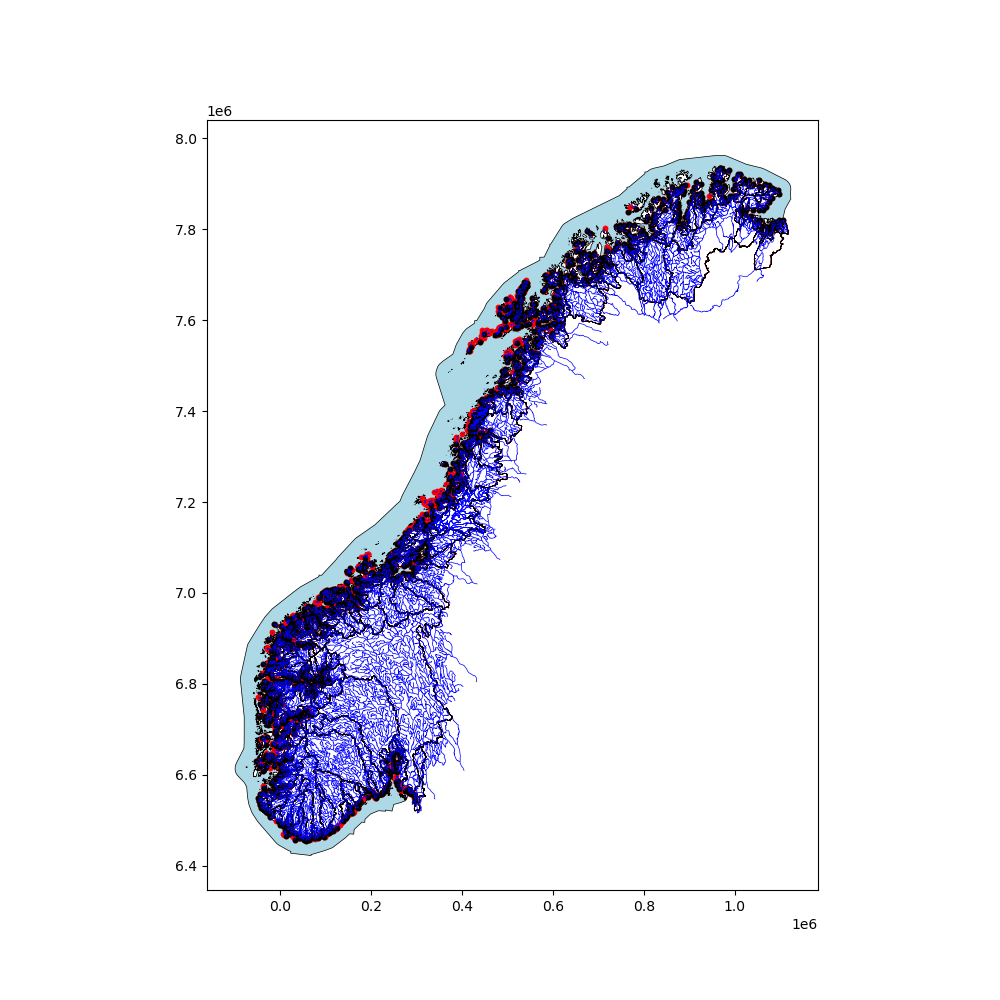

In [9]:
# Plot
ax = sea_gdf.plot(facecolor="lightblue", edgecolor="k", lw=0.5, figsize=(10, 10))
# cat_gdf.clip(bbox).plot(ax=ax, lw=0.5, edgecolor="k", facecolor="none")
cat_gdf.plot(ax=ax, lw=0.5, edgecolor="r", facecolor="none")
select_cats_gdf.plot(ax=ax, lw=0.5, edgecolor="k", facecolor="none")
riv_gdf.plot(ax=ax, lw=0.5, edgecolor="blue")
outlet_gdf.plot(ax=ax, marker='o', color='r', markersize=10)
select_outlets_gdf.plot(ax=ax, marker="o", color="k", edgecolor="black", markersize=10)

# plt.savefig(os.path.join(output_dir, f"map-outlets-catchments_min-size-{min_cat_size}km2_kept-vs-dropped.png"))
plt.show()

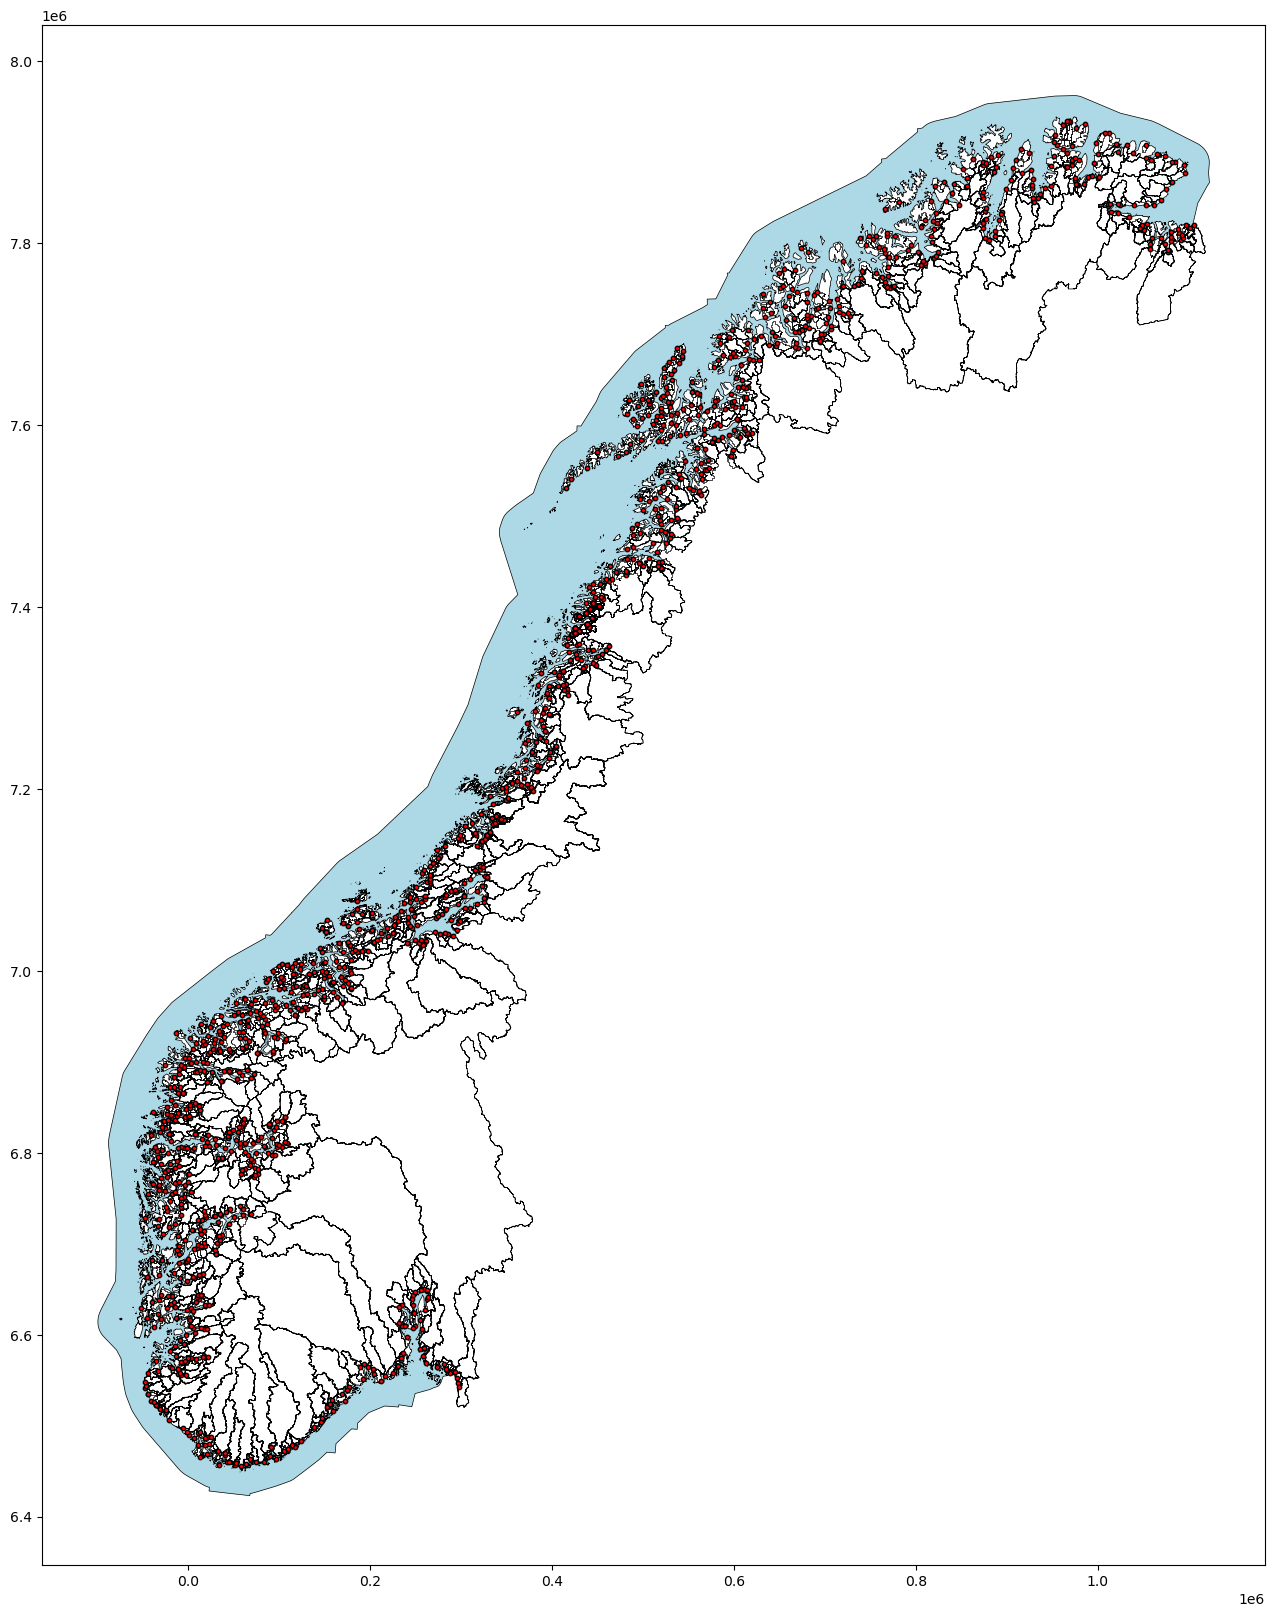

In [15]:
# Plot
%matplotlib inline
ax = sea_gdf.plot(facecolor="lightblue", edgecolor="k", lw=0.5, figsize=(20, 20))
select_cats_gdf.plot(ax=ax, lw=0.5, edgecolor="k", facecolor="none")
# riv_gdf.plot(ax=ax, lw=0.5, edgecolor="blue")
select_outlets_gdf.plot(ax=ax, marker="o", color="red", edgecolor="black", markersize=10)

plt.savefig(os.path.join(cur_dir, f"map-outlets-catchments_min-size-{min_cat_size}km2_merged_norivs.png"))
plt.show()

In [ ]:
# Code for doing euclidian allocation pixel-wise...
# Runs, but causes an INCREASE in the number of catchments... So drop for now.

# # Rasterize the catchments
    # resolution = 1000   # metres

    # small_ids = cat_gdf.loc[cat_gdf["area_km2"] < min_cat_size, "elvid"].tolist()
    # large_ids = cat_gdf.loc[cat_gdf["area_km2"] >= min_cat_size, "elvid"].tolist()

    # # Create a raster grid
    # minx, miny, maxx, maxy = cat_gdf.total_bounds
    # width  = int((maxx - minx) / resolution)
    # height = int((maxy - miny) / resolution)
    
    # transform = rasterio.transform.from_origin(minx, maxy, resolution, resolution)
    
    # basins_arr = features.rasterize(
    #     ((geom, bid) for geom, bid in zip(cat_gdf.geometry, cat_gdf["elvid"])),
    #     out_shape=(height, width),
    #     transform=transform,
    #     fill=0,
    #     dtype="int32"
    # )

    # # Remove small basins (set to 0 / no data)
    # mask = np.isin(basins_arr, small_ids)
    # basins_removed = basins_arr.copy()
    # basins_removed[mask] = 0

    # # Euclidean allocation
    # wbt = WhiteboxTools()

    # wbt_dir = r"/home/jovyan/misc_ljb/temp"
    # wbt.set_working_dir(wbt_dir)
    # in_raster = os.path.join(wbt_dir, "basins_removed.tif")
    # alloc_raster = os.path.join(wbt_dir, "basins_allocated.tif")
    
    # with rasterio.open(
    #     in_raster, "w",
    #     driver="GTiff",
    #     height=height, width=width,
    #     count=1,
    #     dtype="int32",
    #     transform=transform,
    #     crs=cat_gdf.crs
    # ) as dst:
    #     dst.write(basins_removed, 1)

    # # Make sure the input raster exists
    # assert os.path.exists(in_raster), f"Input raster not found: {in_raster}"

    # # Run allocation
    # wbt.euclidean_allocation(i=in_raster, output=alloc_raster)

    # # Verify output
    # assert os.path.exists(alloc_raster), "WhiteboxTools did not create the output file!"


    # # Mask out sea pixels (wrongly allocated to nearest valid basin)
    # sea_arr = features.rasterize(
    #     [(sea_gdf.geometry.iloc[0], 1)],
    #     out_shape=(height, width),
    #     transform=transform,
    #     fill=0,
    #     dtype="uint8"
    # )
    
    # with rasterio.open(alloc_raster) as src:
    #     alloc = src.read(1)
    
    # alloc[sea_arr == 1] = 0  # mask ocean again

    # # Convert back to polygons
    # polys = []
    # ids = []
    
    # for geom, val in shapes(alloc, transform=transform):
    #     if val != 0:
    #         polys.append(sg.shape(geom))
    #         ids.append(val)
    
    # select_cats_gdf = gpd.GeoDataFrame({"elvid": ids}, geometry=polys, crs=cat_gdf.crs)